In [2]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


#### Import dependencies

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
train = pd.read_csv("data/train.csv")
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


Excluding Name, PassengerId and Survived, there are 5 numerical features and 4 categorical features

In [5]:
train.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [6]:
train["Survived"].mean()

np.float64(0.3838383838383838)

Text(0.5, 1.0, 'Survival rate by Sex')

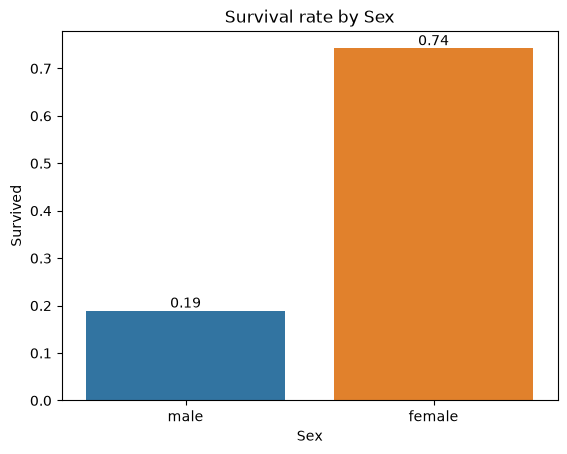

In [7]:
ax = sns.barplot(train, x = 'Sex', y = 'Survived', hue = 'Sex', errorbar = None)
for i in range(len(ax.containers)):
    ax.bar_label(ax.containers[i], fontsize=10, fmt="%.2f")
ax.set_title('Survival rate by Sex')

Female are more likely to survive than male.

Text(0.5, 1.0, 'Percentage of Survivors by Passenger Class')

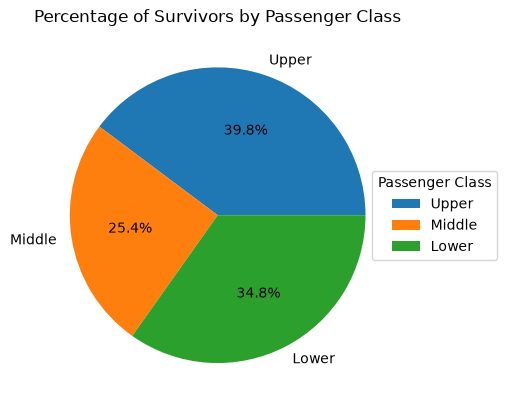

In [8]:
class_labels = {1: 'Upper', 2: 'Middle', 3: 'Lower'}
survivors_by_class = train[train['Survived'] == 1].groupby('Pclass')['Survived'].count()

plt.pie(
    survivors_by_class,
    labels = [class_labels[p] for p in survivors_by_class.index],
    autopct = '%1.1f%%'
)
plt.legend([class_labels[p] for p in survivors_by_class.index], title = "Passenger Class", loc = "center left", bbox_to_anchor = (0.9, 0.5))
plt.title('Percentage of Survivors by Passenger Class')

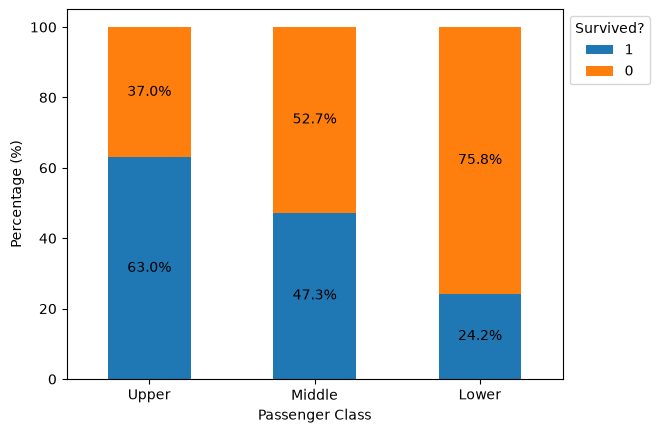

In [9]:
survival_rate_by_class = pd.crosstab(train['Pclass'], train['Survived'], normalize = 'index') * 100
survival_rate_by_class = survival_rate_by_class[[1, 0]]
survival_rate_by_class.index = ['Upper', 'Middle', 'Lower']
ax = survival_rate_by_class.plot(kind = "bar", stacked = True, rot = 0)
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f%%',
        label_type = 'center'
    )
plt.xlabel('Passenger Class')
plt.ylabel('Percentage (%)')
plt.legend(title = 'Survived?', bbox_to_anchor = (1, 1))


In [10]:
train['Pclass'].value_counts()

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

The pie chart shows that in the survived group, upper and lower class constitute the most.  
The stacked bar shows that the higher the passenger class, the more likely they are to be survived.  
Although lower class has the most amount of passenger, its percentage in the survived group still lower than the upper class.

In [16]:
train['Age group'] = pd.cut(train['Age'],
                            bins = [0, 17, 24, 35, 60, 100],
                            labels = ['Child', 'Young adult', 'Adult', 'Middle Age', 'Elder'])

train['Age group'].value_counts()

Age group
Adult          220
Middle Age     195
Young adult    164
Child          113
Elder           22
Name: count, dtype: int64

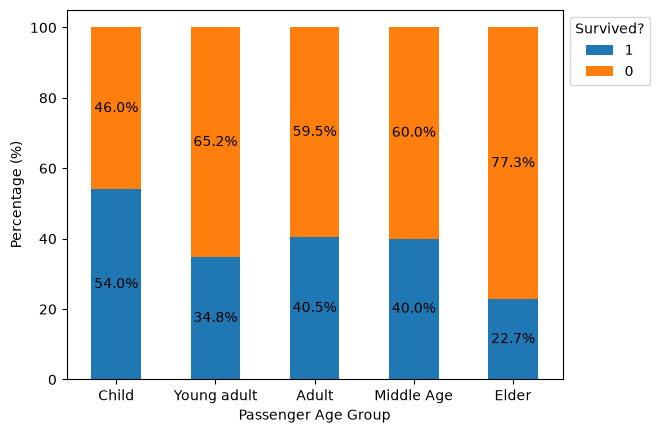

In [19]:
survival_rate_by_agegroup = pd.crosstab(train['Age group'], train['Survived'], normalize = 'index') * 100
survival_rate_by_agegroup = survival_rate_by_agegroup[[1, 0]]
ax = survival_rate_by_agegroup.plot(kind = "bar", stacked = True, rot = 0)
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f%%',
        label_type = 'center'
    )
plt.xlabel('Passenger Age Group')
plt.ylabel('Percentage (%)')
plt.legend(title = 'Survived?', bbox_to_anchor = (1, 1))